In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.shape

(200000, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [5]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [6]:
df.dropna(inplace=True)
df.drop(columns=['Unnamed: 0','key'],inplace=True,errors='ignore')
df.head()
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [7]:
df['pickup_datetime'] = pd.to_datetime( df['pickup_datetime'] , utc=True )
time_row = df['pickup_datetime']

df['hour'] = time_row.dt.hour
df['day'] = time_row.dt.day
df['month'] = time_row.dt.month
df['year'] = time_row.dt.year

df.drop('pickup_datetime',axis=1,inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199999 non-null  float64
 1   pickup_longitude   199999 non-null  float64
 2   pickup_latitude    199999 non-null  float64
 3   dropoff_longitude  199999 non-null  float64
 4   dropoff_latitude   199999 non-null  float64
 5   passenger_count    199999 non-null  int64  
 6   hour               199999 non-null  int32  
 7   day                199999 non-null  int32  
 8   month              199999 non-null  int32  
 9   year               199999 non-null  int32  
dtypes: float64(5), int32(4), int64(1)
memory usage: 13.7 MB


In [8]:
import math
def eucli_dist(lat1,lon1,lat2,lon2):
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    distance = math.sqrt(dlat**2 + dlon**2)
    return distance

df['dist']= df.apply(
    lambda row : eucli_dist(
        row['pickup_latitude'],
        row['pickup_longitude'],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ) ,axis=1
)    

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

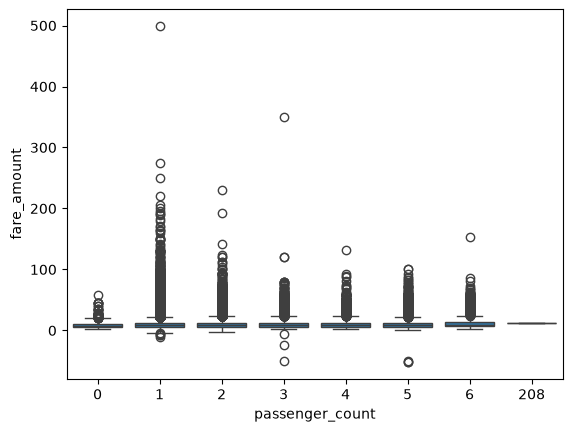

In [9]:
sns.boxplot(y=df['fare_amount'],x=df['passenger_count'])

<Axes: xlabel='passenger_count', ylabel='fare_amount'>

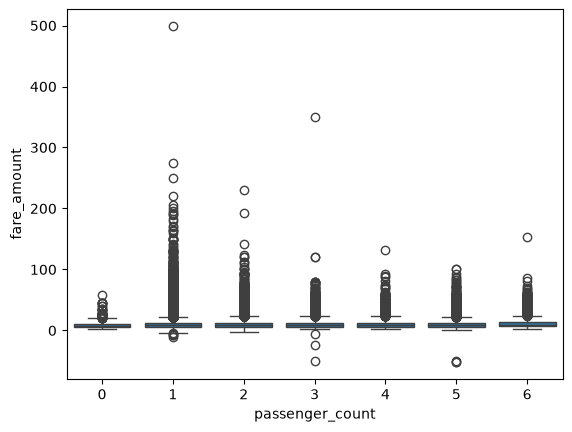

In [10]:
df = df[df['passenger_count']<150]
sns.boxplot(y=df['fare_amount'],x=df['passenger_count'])

In [11]:
df.corr()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dist
fare_amount,1.000000,0.010458,-0.008482,0.008986,-0.011014,0.010745,-0.021462,0.001383,0.023812,0.118331,0.011424
pickup_longitude,0.010458,1.000000,-0.816461,0.833026,-0.846324,-0.000343,0.002431,0.005184,-0.004664,0.009966,-0.181829
pickup_latitude,-0.008482,-0.816461,1.000000,-0.774787,0.702367,-0.001738,-0.003821,-0.008264,0.004624,-0.010233,0.431048
dropoff_longitude,0.008986,0.833026,-0.774787,1.000000,-0.917010,0.000120,0.003477,0.005056,-0.003605,0.008467,-0.142754
dropoff_latitude,-0.011014,-0.846324,0.702367,-0.917010,1.000000,-0.000796,-0.002544,-0.007836,0.003817,-0.011239,-0.063808
passenger_count,0.010745,-0.000343,-0.001738,0.000120,-0.000796,1.000000,0.014649,0.002321,0.009053,0.005833,-0.001679
hour,-0.021462,0.002431,-0.003821,0.003477,-0.002544,0.014649,1.000000,0.004670,-0.003917,0.002158,-0.003397
day,0.001383,0.005184,-0.008264,0.005056,-0.007836,0.002321,0.004670,1.000000,-0.017370,-0.012159,-0.001353
month,0.023812,-0.004664,0.004624,-0.003605,0.003817,0.009053,-0.003917,-0.017370,1.000000,-0.115853,0.000911
year,0.118331,0.009966,-0.010233,0.008467,-0.011239,0.005833,0.002158,-0.012159,-0.115853,1.000000,0.008864


<Axes: >

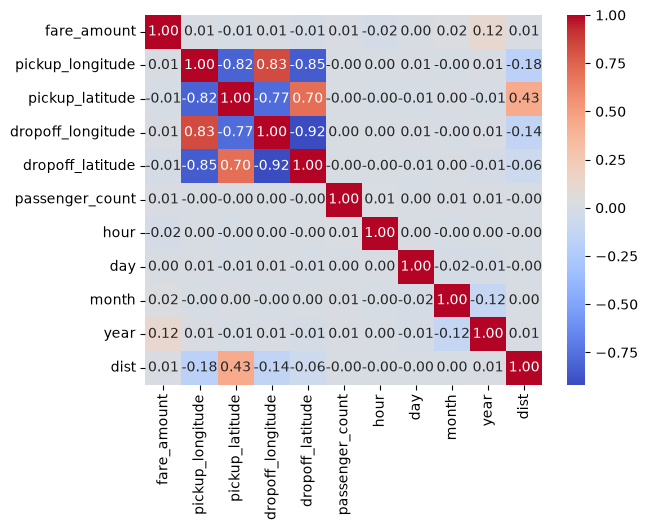

In [12]:
sns.heatmap(df.corr(),annot=True , fmt='.2f' , cmap='coolwarm')

In [13]:
df.corr()['fare_amount'].sort_values(ascending=False)

fare_amount          1.000000
year                 0.118331
month                0.023812
dist                 0.011424
passenger_count      0.010745
pickup_longitude     0.010458
dropoff_longitude    0.008986
day                  0.001383
pickup_latitude     -0.008482
dropoff_latitude    -0.011014
hour                -0.021462
Name: fare_amount, dtype: float64

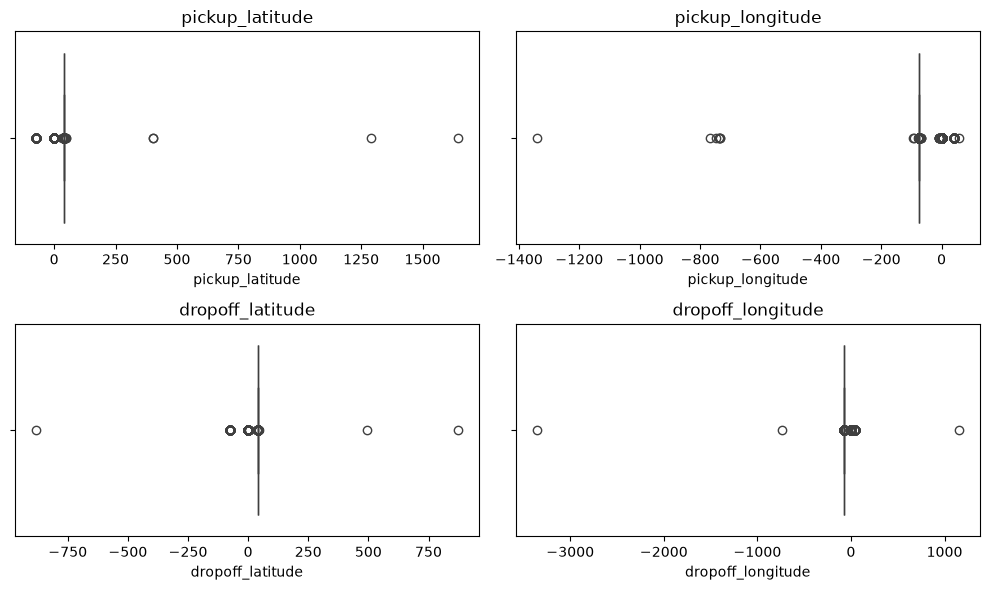

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

sns.boxplot(x=df['pickup_latitude'],ax=axes[0,0])
axes[0,0].set_title('pickup_latitude')
sns.boxplot(x=df['pickup_longitude'],ax=axes[0,1])
axes[0,1].set_title('pickup_longitude')
sns.boxplot(x=df['dropoff_latitude'],ax=axes[1,0])
axes[1,0].set_title('dropoff_latitude')
sns.boxplot(x=df['dropoff_longitude'],ax=axes[1,1])
axes[1,1].set_title('dropoff_longitude')

plt.tight_layout()
plt.show()

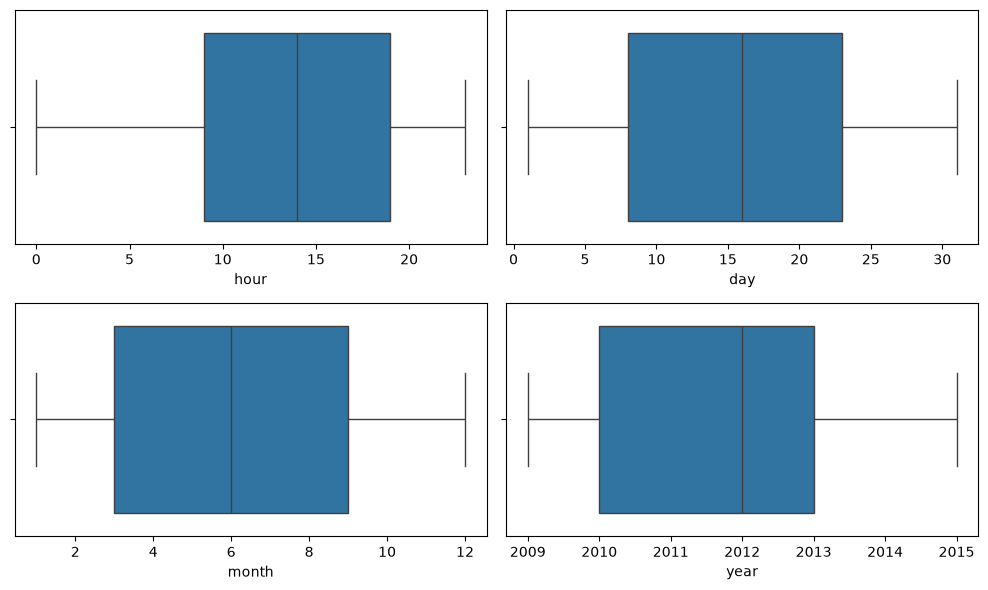

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

sns.boxplot(x=df['hour'],ax=axes[0,0])
sns.boxplot(x=df['day'],ax=axes[0,1])
sns.boxplot(x=df['month'],ax=axes[1,0])
sns.boxplot(x=df['year'],ax=axes[1,1])

plt.tight_layout()
plt.show()

In [16]:
def remove_outliers(feature):
    global df
    q3, q1 = np.percentile(df[feature], [75, 25])
    iqr = q3-q1
    df = df[ (df[feature] >= q1-1.5*iqr) & (df[feature] <= q3+1.5*iqr) ]

remove_outliers("pickup_latitude")
remove_outliers("pickup_longitude")
remove_outliers("dropoff_latitude")
remove_outliers("dropoff_longitude")

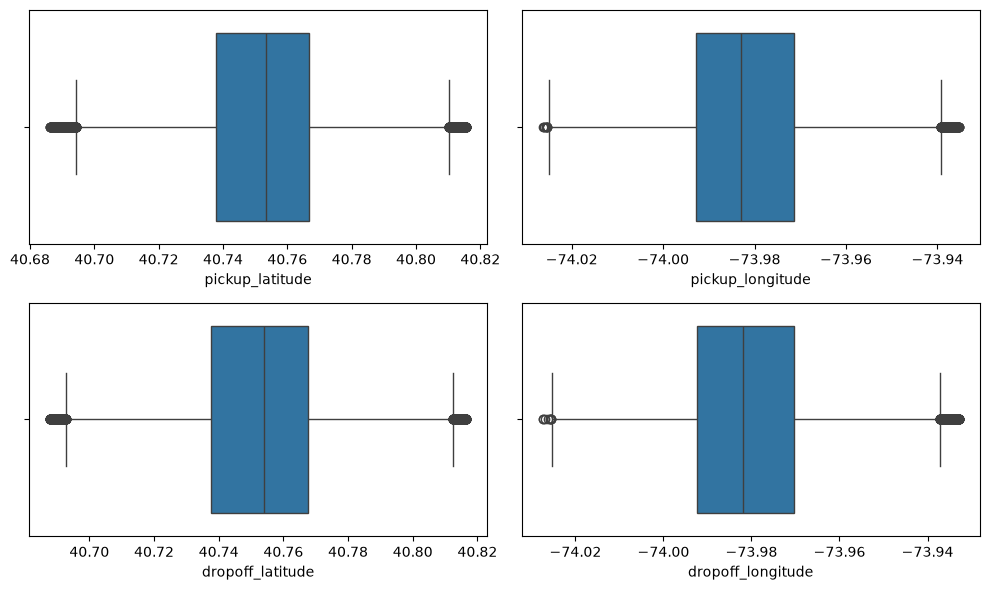

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

sns.boxplot(x=df['pickup_latitude'],ax=axes[0,0])
sns.boxplot(x=df['pickup_longitude'],ax=axes[0,1])
sns.boxplot(x=df['dropoff_latitude'],ax=axes[1,0])
sns.boxplot(x=df['dropoff_longitude'],ax=axes[1,1])

plt.tight_layout()
plt.show()

<Axes: >

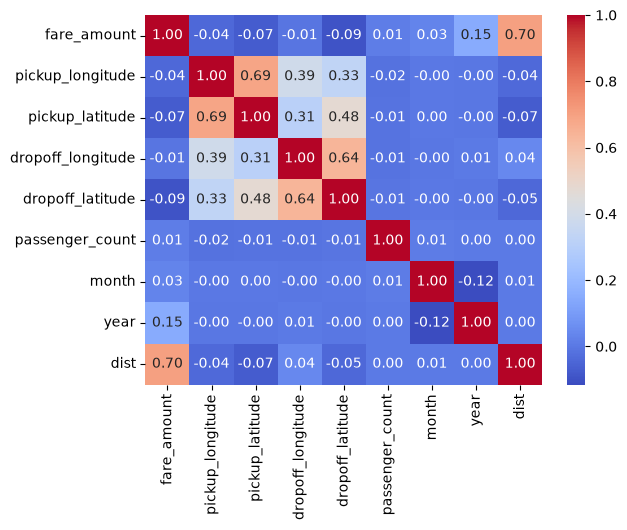

In [18]:
df1 = df.drop(columns=['day','hour'])
sns.heatmap(df1.corr(),annot=True , fmt='.2f' , cmap='coolwarm')

In [19]:
df.corr()['fare_amount'].sort_values(ascending=False)

fare_amount          1.000000
dist                 0.702842
year                 0.148265
month                0.028860
passenger_count      0.011859
day                  0.004195
hour                -0.000569
dropoff_longitude   -0.009266
pickup_longitude    -0.042198
pickup_latitude     -0.072991
dropoff_latitude    -0.093634
Name: fare_amount, dtype: float64

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_scaled,y_train)

y_pred = model.predict(X_test_scaled)
y_pred

array([ 6.98783591, 10.14835166,  9.02042222, ...,  5.77244628,
        6.31249416, 11.23213189], shape=(51355,))

In [30]:
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error

print("R2 score: ", r2_score(y_test,y_pred))
print("RMSE", root_mean_squared_error(y_test,y_pred))

R2 score:  0.5309760466121015
RMSE 3.327151070657858


In [38]:
from sklearn.ensemble import RandomForestRegressor

model1 = RandomForestRegressor()
model1.fit(X_train_scaled, y_train)

y_pred1 = model1.predict(X_test_scaled)
y_pred1

array([ 8.8099,  9.791 ,  8.79  , ...,  5.821 ,  6.045 , 10.856 ],
      shape=(51355,))

In [39]:
print("R2 score: ", r2_score(y_test,y_pred1))
print("RMSE", root_mean_squared_error(y_test,y_pred1))

R2 score:  0.6013280434168106
RMSE 3.06748786201875
